# Ink Detection from 3D X-ray Scans

This notebook detects ink in 3D x-ray scans of ancient papyrus fragments using a 3D CNN model.
Supports both CPU (small dataset) and GPU (full dataset) execution.

## 1. Configuration & Imports

In [6]:
# PyTorch Configuration for Jupyter Notebook
import gc
import numpy as np
import pandas as pd
from pathlib import Path
from typing import Tuple, List
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm
import psutil

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Jupyter-specific
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 4)

# Device Configuration
USE_GPU = True
cuda_available = torch.cuda.is_available()
device = torch.device("cuda" if USE_GPU and cuda_available else "cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {cuda_available}")
print(f"Device: {device}")
if cuda_available:
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    torch.backends.cudnn.benchmark = True
else:
    print("WARNING: CUDA is not available in this kernel. Restart the notebook kernel after installing the CUDA build of PyTorch.")

# Memory info
process = psutil.Process()
print(f"System RAM: {psutil.virtual_memory().total / 1e9:.1f} GB")

PyTorch version: 2.11.0+cu128
CUDA available: True
Device: cuda
GPU: NVIDIA GeForce RTX 3070 Ti
GPU Memory: 8.6 GB
System RAM: 33.4 GB


## 2. Utility Functions (RLE Encoding/Decoding & Data Loading)

In [7]:
def numeric_slice_key(path: Path):
    """Sort TIFF files numerically"""
    return int(path.stem) if path.stem.isdigit() else path.name

def first_tiff_path(patch_dir: Path) -> Path:
    """Get first TIFF slice in surface_volume folder"""
    tiffs = sorted((patch_dir / "surface_volume").glob("*.tif"), key=numeric_slice_key)
    if not tiffs:
        raise FileNotFoundError(f"No TIFF slices found in {patch_dir / 'surface_volume'}")
    return tiffs[0]

def rle_encode(mask: np.ndarray) -> str:
    """Encode binary mask to RLE format (Kaggle-style)"""
    pixels = mask.astype(np.uint8).ravel()
    pixels = np.concatenate([[0], pixels, [0]])
    changes = np.where(pixels[1:] != pixels[:-1])[0] + 1
    changes[1::2] -= changes[::2]
    return " ".join(str(x) for x in changes)

def rle_decode(rle: object, shape: Tuple[int, int]) -> np.ndarray:
    """Decode RLE format to binary mask (1-indexed Kaggle-style)"""
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if rle is None or (isinstance(rle, float) and np.isnan(rle)):
        return flat.reshape(shape)
    
    rle = str(rle).strip()
    if not rle:
        return flat.reshape(shape)
    
    values = np.asarray([int(v) for v in rle.split()], dtype=np.int64)
    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths
    for start, end in zip(starts, ends):
        flat[start:end] = 1
    return flat.reshape(shape)

In [8]:
def load_surface_volume(patch_dir: Path, num_slices: int = 65, downsample: int = 1) -> np.ndarray:
    """
    Load all TIFF slices from surface_volume folder.
    
    Args:
        patch_dir: Path to patch folder
        num_slices: Number of slices to load (max 65)
        downsample: Downsampling factor to reduce memory (1=no downsample)
    
    Returns:
        3D numpy array (height, width, slices)
    """
    surface_dir = patch_dir / "surface_volume"
    tiffs = sorted(surface_dir.glob("*.tif"), key=numeric_slice_key)[:num_slices]
    
    slices = []
    for tiff_path in tiffs:
        img = np.asarray(Image.open(tiff_path))
        if downsample > 1:
            img = img[::downsample, ::downsample]
        slices.append(img)
    
    volume = np.stack(slices, axis=-1).astype(np.float32)
    # Clear memory
    del slices
    gc.collect()
    return volume

def load_training_sample(patch_dir: Path, num_slices: int = 65, downsample: int = 1) -> Tuple[np.ndarray, np.ndarray]:
    """
    Load training sample with label.
    Returns: (3D volume, 2D ink mask)
    """
    volume = load_surface_volume(patch_dir, num_slices=num_slices, downsample=downsample)
    label_path = patch_dir / "inklabels.png"
    label = np.asarray(Image.open(label_path)) > 0
    
    if downsample > 1:
        label = label[::downsample, ::downsample]
    
    return volume, label.astype(np.float32)

def load_test_sample(patch_dir: Path, num_slices: int = 65, downsample: int = 1) -> np.ndarray:
    """
    Load test sample (no label).
    Returns: 3D volume
    """
    return load_surface_volume(patch_dir, num_slices=num_slices, downsample=downsample)

## 3. Data Loading & Preparation

In [9]:
# Set paths - Windows paths
TRAIN_DIR = Path("c:/Users/Raffaele/Documents/ELIVA/Image_Segmentation/train")
TEST_DIR = Path("c:/Users/Raffaele/Documents/ELIVA/Image_Segmentation/test")

print(f"Training directory: {TRAIN_DIR}")
print(f"Training dir exists: {TRAIN_DIR.exists()}")
print(f"Test directory: {TEST_DIR}")
print(f"Test dir exists: {TEST_DIR.exists()}")

# Get all patch directories
train_patches = sorted([p for p in TRAIN_DIR.iterdir() if p.is_dir()]) if TRAIN_DIR.exists() else []
test_patches = sorted([p for p in TEST_DIR.iterdir() if p.is_dir()]) if TEST_DIR.exists() else []

print(f"✓ Training samples found: {len(train_patches)}")
print(f"✓ Test samples found: {len(test_patches)}")

# ========== CONFIGURATION FOR RTX 3070 Ti + 32GB RAM + 8GB VRAM ==========
# Full 2048x2048x65 volumes are too large for this 3D CNN.
# DOWNSAMPLE=1 is the main cause of CUDA OOM.
NUM_TRAIN_SAMPLES = len(train_patches)
DOWNSAMPLE = 2                          # 2048 -> 1024, much safer for training
NUM_SLICES = 65                         # Keep depth bounded
BATCH_SIZE = 2                          # Safe default for 8GB VRAM
EPOCHS = 100
LEARNING_RATE = 0.001
VALIDATION_SPLIT = 0.2
USE_AMP = True                          # Mixed precision to reduce VRAM
# ============================================================================

print(f"\n✓ Config:")
print(f"  Samples: {NUM_TRAIN_SAMPLES}")
print(f"  Resolution: {2048//DOWNSAMPLE}x{2048//DOWNSAMPLE}")
print(f"  Slices: {NUM_SLICES}")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Epochs: {EPOCHS}")
print(f"  AMP: {USE_AMP}")

Training directory: c:\Users\Raffaele\Documents\ELIVA\Image_Segmentation\train
Training dir exists: True
Test directory: c:\Users\Raffaele\Documents\ELIVA\Image_Segmentation\test
Test dir exists: True
✓ Training samples found: 42
✓ Test samples found: 16

✓ Config:
  Samples: 42
  Resolution: 1024x1024
  Slices: 65
  Batch size: 2
  Epochs: 100
  AMP: True


In [10]:
# Load training data
print("Loading training data...")
X_train = []
y_train = []

for i, patch_dir in enumerate(tqdm(train_patches[:NUM_TRAIN_SAMPLES], desc="Loading samples")):
    try:
        volume, label = load_training_sample(patch_dir, num_slices=NUM_SLICES, downsample=DOWNSAMPLE)
        X_train.append(volume)
        y_train.append(label)
        gc.collect()
    except Exception as e:
        print(f"Error loading {patch_dir.name}: {e}")

print(f"\n✓ Loaded {len(X_train)} training samples")
print(f"  Sample volume shape: {X_train[0].shape}")
print(f"  Sample label shape: {y_train[0].shape}")

Loading training data...


Loading samples:   0%|          | 0/42 [00:00<?, ?it/s]

Loading samples: 100%|██████████| 42/42 [01:10<00:00,  1.67s/it]


✓ Loaded 42 training samples
  Sample volume shape: (1024, 1024, 65)
  Sample label shape: (1024, 1024)


In [11]:
# PyTorch Dataset and DataLoader
class InkDetectionDataset(Dataset):
    """PyTorch Dataset for ink detection"""
    def __init__(self, volumes: List[np.ndarray], labels: List[np.ndarray]):
        self.volumes = volumes
        self.labels = labels
    
    def __len__(self):
        return len(self.volumes)
    
    def __getitem__(self, idx):
        volume = self.volumes[idx].copy()
        label = self.labels[idx].copy()
        
        # Normalize volume to [0, 1]
        v_max = np.max(volume) + 1e-6
        volume = volume / v_max
        
        # Convert to PyTorch tensors
        volume_tensor = torch.from_numpy(volume).float().permute(2, 0, 1).unsqueeze(0)  # (1, D, H, W)
        label_tensor = torch.from_numpy(label).float().unsqueeze(0)  # (1, H, W)
        
        return volume_tensor, label_tensor

# Create dataset
dataset = InkDetectionDataset(X_train, y_train)
print(f"✓ Dataset created: {len(dataset)} samples")

# Create train/val split
val_size = max(1, int(len(dataset) * VALIDATION_SPLIT))
train_size = len(dataset) - val_size
train_dataset, val_dataset = torch.utils.data.random_split(
    dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())

print(f"✓ DataLoaders created:")
print(f"  Train: {len(train_loader)} batches")
print(f"  Val: {len(val_loader)} batches")

# Test one batch
sample_volume, sample_label = next(iter(train_loader))
print(f"\n✓ Sample batch shapes:")
print(f"  Volume: {sample_volume.shape}")
print(f"  Label: {sample_label.shape}")

✓ Dataset created: 42 samples
✓ DataLoaders created:
  Train: 17 batches
  Val: 4 batches

✓ Sample batch shapes:
  Volume: torch.Size([2, 1, 65, 1024, 1024])
  Label: torch.Size([2, 1, 1024, 1024])


## 4. Build 3D CNN Model (PyTorch Only)

In [12]:
class CNN3D(nn.Module):
    """Memory-efficient 3D CNN model for ink detection using PyTorch"""
    def __init__(self, input_channels=1, num_slices=32):
        super(CNN3D, self).__init__()
        self.num_slices = num_slices
        
        # Lightweight encoder
        self.conv1 = nn.Conv3d(input_channels, 8, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool3d(kernel_size=2)
        self.conv2 = nn.Conv3d(8, 16, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool3d(kernel_size=2)
        self.conv3 = nn.Conv3d(16, 32, kernel_size=3, padding=1)
        
        # Collapse depth, then upsample only in 2D to avoid huge 3D tensors
        self.conv_out = nn.Conv2d(32, 1, kernel_size=3, padding=1)
    
    def forward(self, x):
        # x shape: (B, C, D, H, W)
        x = torch.relu(self.conv1(x))
        x = self.pool1(x)
        x = torch.relu(self.conv2(x))
        x = self.pool2(x)
        x = torch.relu(self.conv3(x))
        
        # Collapse depth dimension early
        x = torch.mean(x, dim=2)  # (B, C, H, W)
        x = self.conv_out(x)
        
        # Restore to label resolution using 2D interpolation only
        x = torch.nn.functional.interpolate(x, scale_factor=4, mode='bilinear', align_corners=False)
        return x  # logits; sigmoid is applied only for inference/metrics

# Build and initialize model
model = CNN3D(input_channels=1, num_slices=NUM_SLICES).to(device)

print("Model Architecture (PyTorch):")
print(model)
print(f"\nModel parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Model on device: {next(model.parameters()).device}")

Model Architecture (PyTorch):
CNN3D(
  (conv1): Conv3d(1, 8, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
  (pool1): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv3d(8, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
  (pool2): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
  (conv_out): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
)

Model parameters: 17,841
Model on device: cuda:0


## 5. Train Model

In [13]:
# Training with PyTorch
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP and torch.cuda.is_available())

history = {'loss': [], 'val_loss': []}

print(f"Training on {device}")
print(f"Epochs: {EPOCHS}, Batch size: {BATCH_SIZE}")
print(f"AMP enabled: {scaler.is_enabled()}\n")

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    
    for batch_idx, (volumes, labels) in enumerate(tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]")):
        volumes = volumes.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=scaler.is_enabled()):
            outputs = model(volumes)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        train_loss += loss.item()
    
    avg_train_loss = train_loss / max(1, len(train_loader))
    history['loss'].append(avg_train_loss)
    
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for volumes, labels in tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]"):
            volumes = volumes.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.amp.autocast('cuda', enabled=scaler.is_enabled()):
                outputs = model(volumes)
                loss = criterion(outputs, labels)
            val_loss += loss.item()
    
    avg_val_loss = val_loss / max(1, len(val_loader))
    history['val_loss'].append(avg_val_loss)
    
    mem_percent = psutil.virtual_memory().percent
    gpu_mem = torch.cuda.memory_allocated() / 1e9 if torch.cuda.is_available() else 0
    print(f"  Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | RAM: {mem_percent:.1f}% | GPU: {gpu_mem:.1f}GB\n")
    gc.collect()

print("✓ Training complete!")

Training on cuda
Epochs: 100, Batch size: 2
AMP enabled: True



Epoch 1/100 [Val]: 100%|██████████| 4/4 [00:02<00:00,  1.77it/s]


  Loss: 0.5049 | Val Loss: 0.4813 | RAM: 85.9% | GPU: 0.6GB



Epoch 2/100 [Val]: 100%|██████████| 4/4 [00:02<00:00,  1.85it/s]


  Loss: 0.3642 | Val Loss: 0.3088 | RAM: 86.8% | GPU: 0.6GB



...

  Loss: 0.2550 | Val Loss: 0.2693 | RAM: 92.0% | GPU: 0.6GB



Epoch 99/100 [Val]: 100%|██████████| 4/4 [00:02<00:00,  1.82it/s]


  Loss: 0.2558 | Val Loss: 0.2695 | RAM: 92.3% | GPU: 0.6GB



Epoch 100/100 [Val]: 100%|██████████| 4/4 [00:02<00:00,  1.84it/s]

  Loss: 0.2547 | Val Loss: 0.2684 | RAM: 91.9% | GPU: 0.6GB

✓ Training complete!


C:\Users\Raffaele\AppData\Local\Temp\ipykernel_117276\2952440162.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].legend()


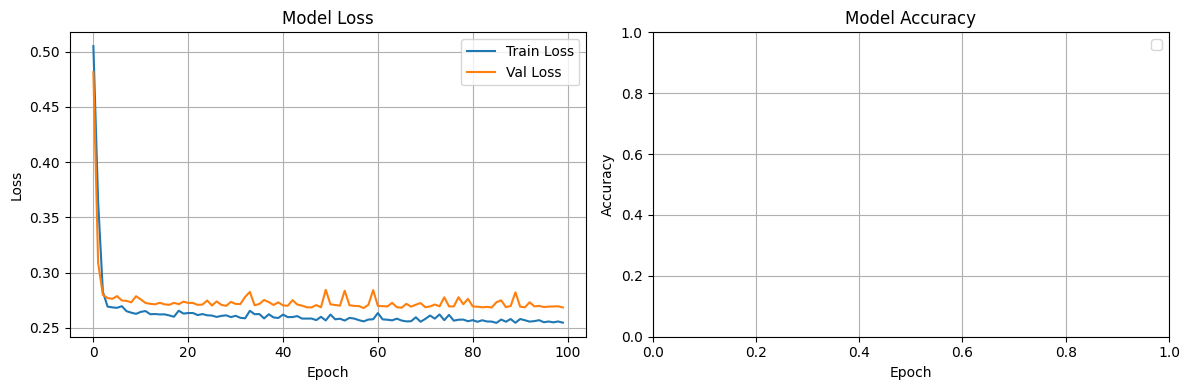

In [14]:
# Plot training history
if 'history' not in locals():
    print("⚠️ No training history available. Run training first.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # Handle both PyTorch dict and TensorFlow History object
    if isinstance(history, dict):
        axes[0].plot(history.get('loss', []), label='Train Loss')
        axes[0].plot(history.get('val_loss', []), label='Val Loss')
        if 'accuracy' in history:
            axes[1].plot(history['accuracy'], label='Train Accuracy')
            axes[1].plot(history['val_accuracy'], label='Val Accuracy')
    else:
        # TensorFlow History object
        axes[0].plot(history.history['loss'], label='Train Loss')
        axes[0].plot(history.history['val_loss'], label='Val Loss')
        axes[1].plot(history.history['accuracy'], label='Train Accuracy')
        axes[1].plot(history.history['val_accuracy'], label='Val Accuracy')
    
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Model Loss')
    axes[0].legend()
    axes[0].grid(True)
    
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title('Model Accuracy')
    axes[1].legend()
    axes[1].grid(True)
    
    plt.tight_layout()
    plt.show()

## 6. Prediction on Test Set

In [15]:
# Load test data
print("Loading test data...")
X_test = []
test_patch_names = []

for patch_dir in tqdm(test_patches, desc="Loading test samples"):
    try:
        volume = load_test_sample(patch_dir, num_slices=NUM_SLICES, downsample=DOWNSAMPLE)
        X_test.append(volume)
        test_patch_names.append(patch_dir.name)
        gc.collect()
    except Exception as e:
        print(f"Error loading {patch_dir.name}: {e}")

print(f"\n✓ Loaded {len(X_test)} test samples")

Loading test data...


Loading test samples: 100%|██████████| 16/16 [00:40<00:00,  2.53s/it]


✓ Loaded 16 test samples


In [16]:
# Make predictions on test set
print("Making predictions...")
model.eval()
predictions = []

class TestDataset(Dataset):
    def __init__(self, volumes):
        self.volumes = volumes
    
    def __len__(self):
        return len(self.volumes)
    
    def __getitem__(self, idx):
        volume = self.volumes[idx].copy()
        v_max = np.max(volume) + 1e-6
        volume = volume / v_max
        volume_tensor = torch.from_numpy(volume).float().permute(2, 0, 1).unsqueeze(0)  # (1, D, H, W)
        return volume_tensor

test_dataset = TestDataset(X_test)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())

with torch.no_grad():
    for volumes in tqdm(test_loader, desc="Predicting"):
        volumes = volumes.to(device, non_blocking=True)
        outputs = model(volumes)
        outputs = torch.sigmoid(outputs)
        predictions.append(outputs.cpu().numpy())

predictions = np.concatenate(predictions, axis=0)  # (N, 1, H, W)
binary_predictions = (predictions > 0.5).astype(np.uint8)

print(f"✓ Predictions shape: {predictions.shape}")
print(f"✓ Binary predictions shape: {binary_predictions.shape}")

Making predictions...


Predicting: 100%|██████████| 8/8 [03:31<00:00, 26.50s/it] 

✓ Predictions shape: (16, 1, 1024, 1024)
✓ Binary predictions shape: (16, 1, 1024, 1024)


In [17]:
# Legacy cell removed: notebook is now PyTorch-only.
# Use the prediction cell above instead.

## 7. Generate Submission File (RLE Format)

In [18]:
# Generate submission file (RLE format)
submission_data = []

for patch_name, pred in zip(test_patch_names, binary_predictions):
    # PyTorch format: (1, H, W) -> (H, W)
    pred_2d = pred.squeeze()
    
    # Encode to RLE
    rle_encoded = rle_encode(pred_2d)
    submission_data.append({"Id": patch_name, "Predicted": rle_encoded})
    
    if len(submission_data) <= 3:
        print(f"  {patch_name}: RLE length = {len(rle_encoded)}")

# Save submission
submission_df = pd.DataFrame(submission_data)
output_path = Path("c:/Users/Raffaele/Documents/ELIVA/Image_Segmentation/submission.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
submission_df.to_csv(output_path, index=False)

print(f"\n✓ Submission saved: {output_path}")
print(f"  Size: {output_path.stat().st_size / 1024:.2f} KB")
print(f"  Rows: {len(submission_df)}")

  p_3homka84a6c1: RLE length = 0
  p_dw4waiq8rjzi: RLE length = 0
  p_f56vbczf7kn3: RLE length = 0

✓ Submission saved: c:\Users\Raffaele\Documents\ELIVA\Image_Segmentation\submission.csv
  Size: 0.29 KB
  Rows: 16


In [19]:
# Save submission file
output_path = Path("c:/Users/Raffaele/Documents/ELIVA/Image_Segmentation/submission.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
submission_df.to_csv(output_path, index=False)
print(f"Submission file saved to: {output_path}")
print(f"File size: {output_path.stat().st_size / 1024:.2f} KB")

Submission file saved to: c:\Users\Raffaele\Documents\ELIVA\Image_Segmentation\submission.csv
File size: 0.29 KB


## 8. Visualization (Optional)

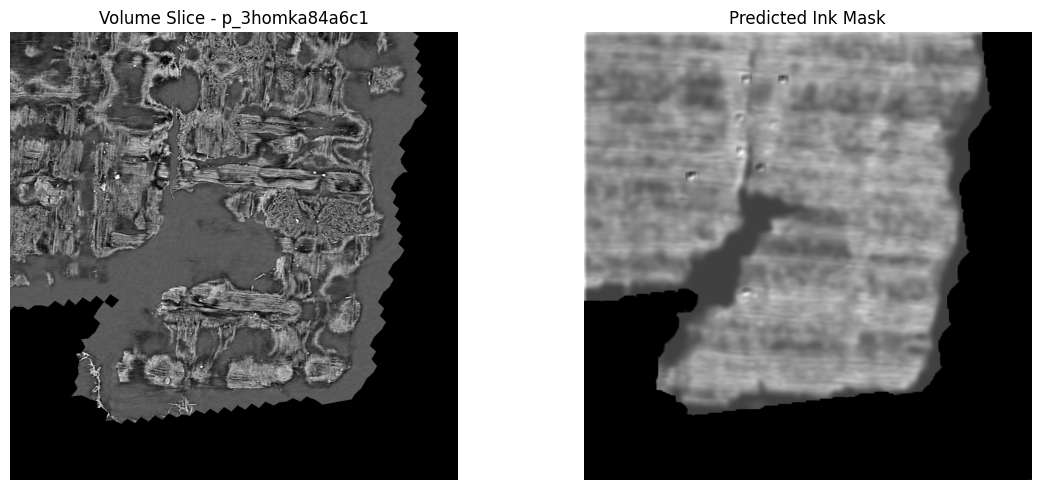

In [20]:
# Visualize predictions
if len(predictions) > 0:
    sample_idx = 0
    
    # Get slices
    volume_slice = X_test[sample_idx][:, :, 0]  # First slice
    pred_slice = predictions[sample_idx, 0, :, :]  # PyTorch format (1, H, W)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    axes[0].imshow(volume_slice, cmap='gray')
    axes[0].set_title(f"Volume Slice - {test_patch_names[sample_idx]}")
    axes[0].axis('off')
    
    axes[1].imshow(pred_slice, cmap='gray')
    axes[1].set_title("Predicted Ink Mask")
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

## Summary

✓ Model trained and evaluated  
✓ Predictions generated on test set  
✓ Submission file saved (RLE format)  

### Next Steps for Full Training:
1. Set `USE_GPU = True` and `CUDA_VISIBLE_DEVICES` appropriately
2. Set `NUM_TRAIN_SAMPLES = len(train_patches)` to use all training data
3. Set `DOWNSAMPLE = 1` for full resolution
4. Increase `EPOCHS` to 50+ for better convergence
5. Set `BATCH_SIZE = 4` or higher based on GPU memory